<a href="https://colab.research.google.com/github/junkim-researcher/turboquant-study1/blob/main/notebooks/exp4_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 4단계 (확장): 키 평균 빼기

## ⚠️ 실행 전에 GPU 켜기
메뉴 **[런타임] → [런타임 유형 변경] → 하드웨어 가속기 `T4 GPU` → [저장]**

그다음 **[런타임] → [모두 실행]** (약 8~12분)

끝나면 **[파일] → [GitHub에 사본 저장]** → 경로 `notebooks/exp4_colab.ipynb` 그대로 → **[확인]**

In [1]:
# 1) GPU 확인
!nvidia-smi -L || echo '⚠️ GPU가 없습니다. [런타임]→[런타임 유형 변경]에서 T4 GPU를 켜고 다시 실행하세요.'

GPU 0: Tesla T4 (UUID: GPU-25f9e359-c1a3-e6e5-176b-274ec98e5bbc)


In [2]:
# 2) 코드 내려받기
!rm -rf /content/turboquant-study1
!git clone -q https://github.com/junkim-researcher/turboquant-study1.git /content/turboquant-study1
%cd /content/turboquant-study1
!git log --oneline -1

/content/turboquant-study1
7f200f0 (HEAD -> main, origin/main, origin/HEAD) 3단계 결과 정리, 4단계 키 평균 빼기 실험 코드


In [3]:
# 3) 글꼴과 라이브러리 준비
!apt-get -qq install -y fonts-noto-cjk > /dev/null 2>&1
!rm -rf ~/.cache/matplotlib
!pip -q install "transformers>=4.48" datasets
import transformers, torch; print('transformers', transformers.__version__, '| torch', torch.__version__)

transformers 5.22.1 | torch 2.14.1+cu130


In [4]:
# 4) 4단계 실험 실행 (3단계 결과 파일 results/exp3_results.json을 함께 사용)
!python exp4_centered.py 2>&1 | grep -v -i -E 'warn|hf_token|secret'

Loading weights: 100%|██████████| 290/290 [00:01<00:00, 238.80it/s]
[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (299078 > 131072). Running this sequence through the model will result in indexing errors
[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (391968 > 131072). Running this sequence through the model will result in indexing errors
모델 Qwen/Qwen2.5-0.5B  {'n_layers': 24, 'n_heads': 14, 'n_kv_heads': 2, 'head_dim': 64}  장치 cuda
키 평균 계산 완료, 압축할 키 길이²: 평균 빼기 전의 40.9% (20초)
재현성 검사: B0 [13.227823491411627, 13.227823491411627], 키 mse b=4 [144.78773199557975, 144.78773199557986]
  k_mse_c_b2  perplexity   255.789  (158초)
  k_mse_c_b3  perplexity    47.629  (225초)
  k_mse_c_b4  perplexity    19.307  (291초)
  k_prod_c_b2  perplexity  2595.959  (358초)
  k_prod_c_b3  perplexity   490.894  (424초)
  k_prod_c_b4  perplexity    73.680  (491초)
완료: 491.6초


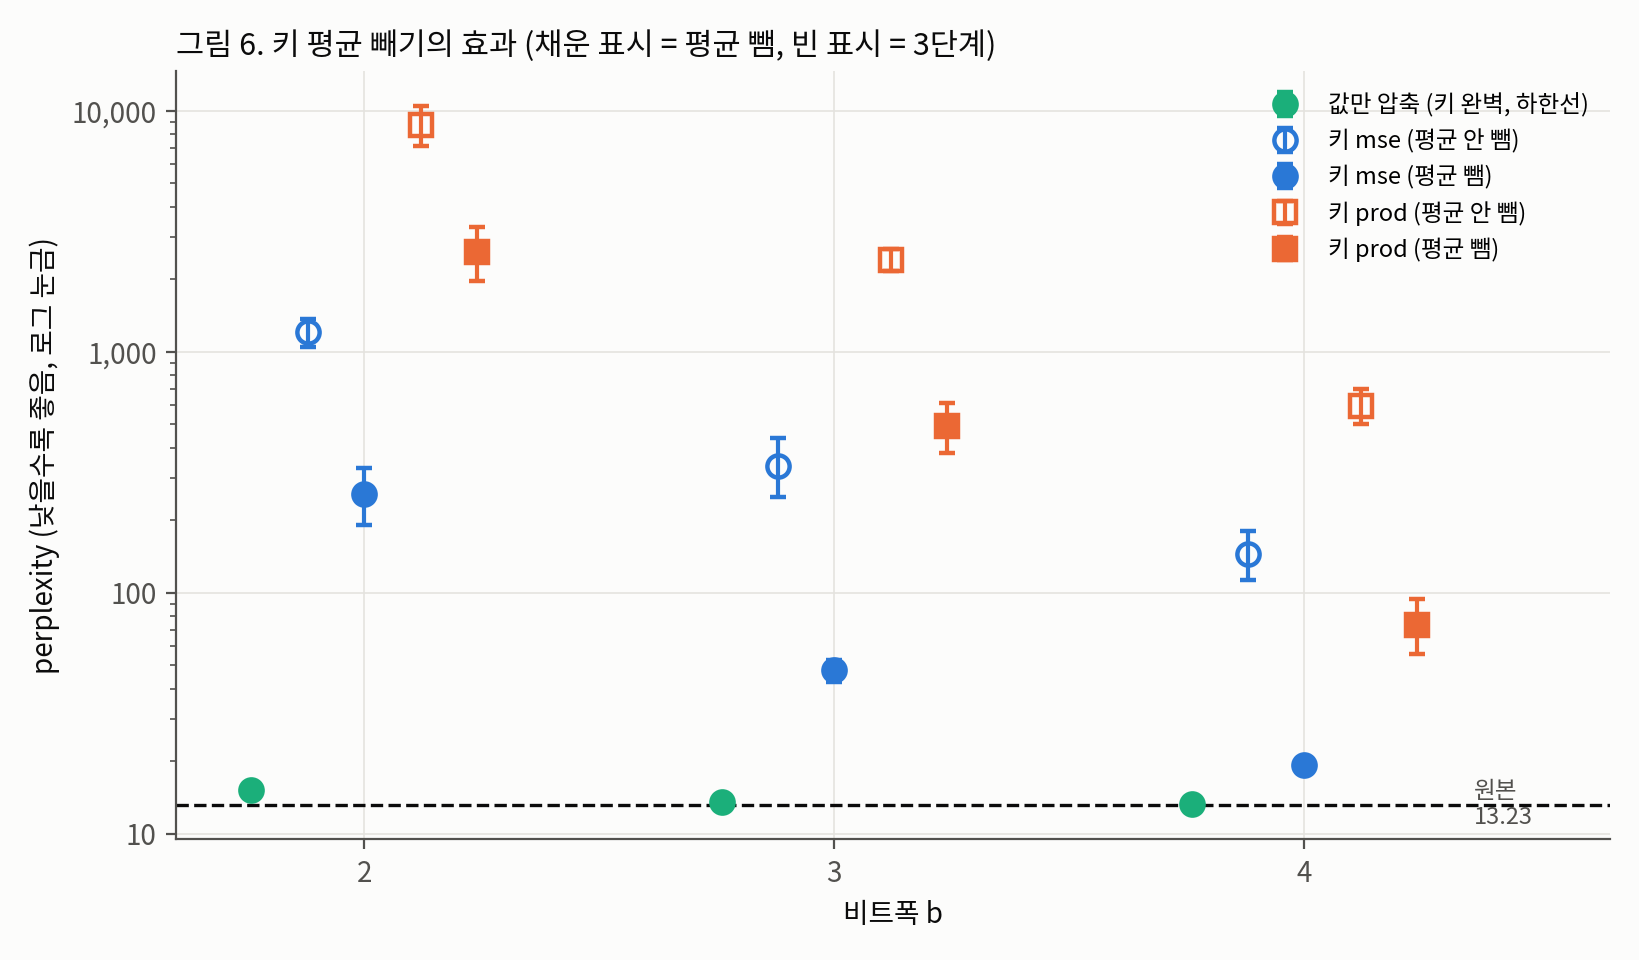

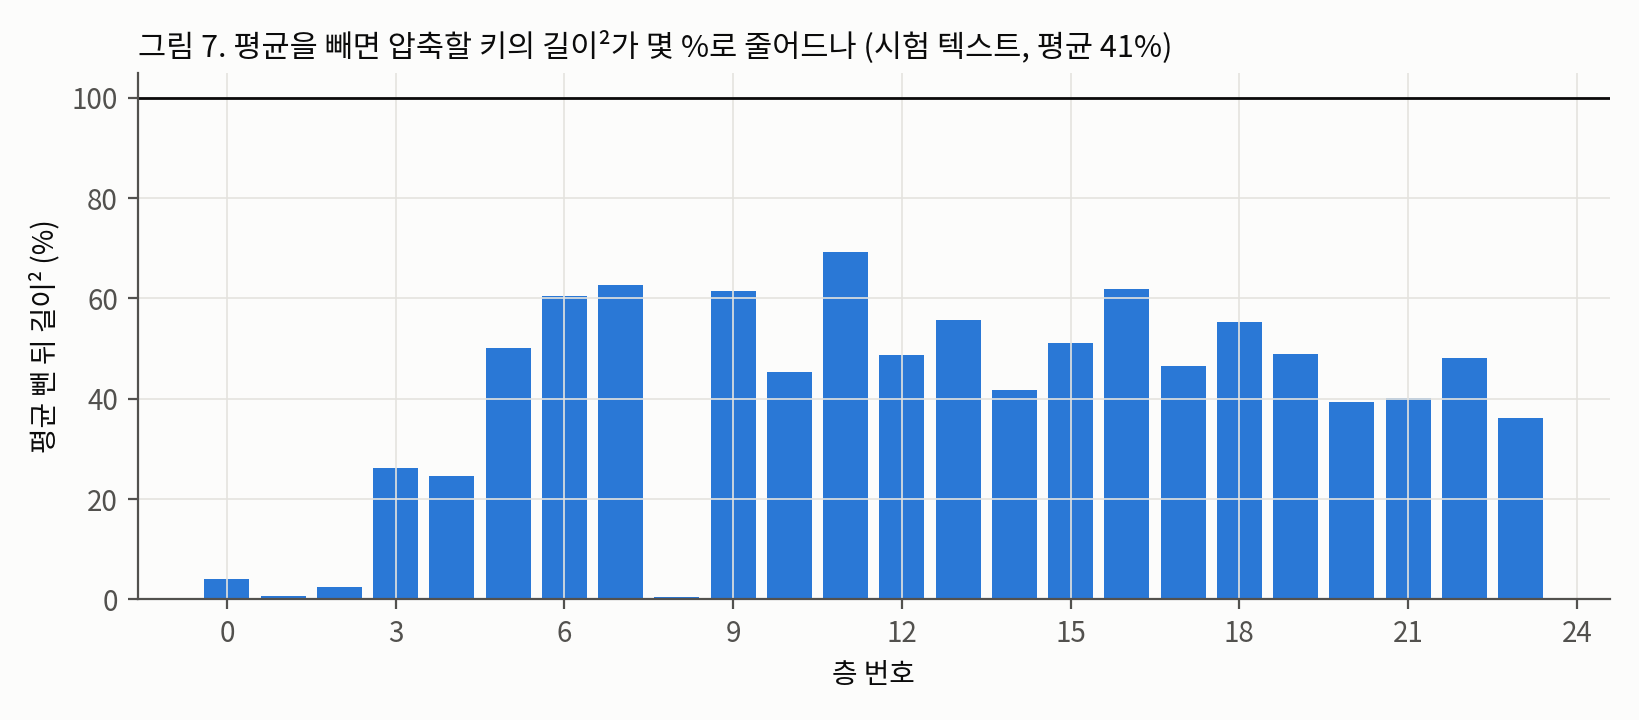

In [5]:
# 5) 그림 보기
from IPython.display import Image, display
display(Image('figures/fig6_centered_perplexity.png', width=850))
display(Image('figures/fig7_centered_norm_reduction.png', width=850))

In [6]:
# 6) 판정 요약
!python summarize_exp4.py

 4단계 판정 요약   4단계 키 평균 빼기
 평균 c를 구한 텍스트: WikiText-2 train 앞부분, 1024토큰 조각 8개   장치 Tesla T4
 재현성 검사(지금 / 3단계): B0 13.228 / 13.228,  키 mse b=4 144.788 / 144.788
 [1] perplexity (원본 B0 = 13.228, 괄호는 원본 대비 배수)
  b |         값만(하한선) |          mse 안 뺌          mse 평균 뺌 |         prod 안 뺌         prod 평균 뺌
  2 |   15.26 (1.15배) |  1203.47 (90.98배)   255.79 (19.34배) |  8713.84 (658.75배)  2595.96 (196.25배)
  3 |   13.59 (1.03배) |   336.96 (25.47배)    47.63 (3.60배) |  2411.00 (182.27배)   490.89 (37.11배)
  4 |   13.31 (1.01배) |   144.79 (10.95배)    19.31 (1.46배) |   598.36 (45.24배)    73.68 (5.57배)
----------------------------------------------------------------------------------------
 [2] 조각 단위 대응 비교 (토큰당 손실 차이, 음수 = 앞의 것이 더 좋음)
   b=2  mse: 평균 뺌 − 안 뺌        -1.5486 [-1.6900, -1.4072]  p_t=1.1e-23  유의 (기준 0.0083)
   b=2  prod: 평균 뺌 − 안 뺌       -1.2110 [-1.2898, -1.1321]  p_t=4.0e-29  유의 (기준 0.0083)
   b=2  평균 뺀 뒤 prod − mse      +2.3174 [+2.1919, +2.4428]  p_t=3.7e-32  유의 (기준 0.0167)
   b=2  평균

In [7]:
# 7) (보관용) 결과 JSON을 노트북 출력에 남기기
import json
r = json.load(open('results/exp4_results.json', encoding='utf-8'))
print(json.dumps(r, ensure_ascii=False))

{"experiment": "4단계 키 평균 빼기", "model": "Qwen/Qwen2.5-0.5B", "dims": {"n_layers": 24, "n_heads": 14, "n_kv_heads": 2, "head_dim": 64}, "data": "WikiText-2 test, 전체 299,078토큰을 1024토큰 조각 292개로 나눠 그중 40개를 고르게 선택", "calibration": "WikiText-2 train 앞부분, 1024토큰 조각 8개", "design": {"bits": [2, 3, 4], "seeds": 5, "chunks": 40, "chunk_len": 1024, "method": "k̂ = c + Q(k − c), c = 층, 키/값 헤드별 키 평균 (보정 텍스트)", "seed_rule": "300000 + 1000*s + layer (3단계와 동일)", "bonferroni": {"centered_vs_not": 0.008333333333333333, "others": 0.016666666666666666}}, "reproducibility_check": {"B0_ppl_now_vs_stage3": [13.227823491411627, 13.227823491411627], "k_mse_b4_ppl_now_vs_stage3": [144.78773199557975, 144.78773199557986]}, "norm_sq_ratio_after_centering": {"0": 0.0399148523603788, "1": 0.007788158086187899, "2": 0.024217640483414443, "3": 0.2627168770256488, "4": 0.24616040322074093, "5": 0.5019809647611456, "6": 0.6040078021676679, "7": 0.6263096614849653, "8": 0.004650851850649046, "9": 0.6152189808036422, "10":